# Day 3 — Natural-Language Explanations of Computer Vision Output

**Module 5: VLMs — VQA, Captioning & Multimodal Embeddings**

Today I will combine a computer-vision result with the original image and ask a vision-language model (VLM) to explain the result in plain language. I will also constrain the response to a JSON structure, parse it, validate its fields, and measure whether the output follows the expected schema.

**What I will do**
- Load a pretrained object detector (YOLO) and run it on an image.
- Pass the image and detector results to Qwen3-VL.
- Ask for a concise, evidence-grounded explanation.
- Request JSON with a fixed schema.
- Parse and validate the JSON, including required keys and value types.
- Test invalid or incomplete outputs with a small validation example.

**Important:** Schema-valid JSON is not necessarily factually correct. Validate the content against the image and detector output.


### 2. Install dependencies

We will use Ultralytics YOLO for object detection and Qwen3-VL for natural-language explanation.

In [1]:
!pip -q install -U ultralytics transformers accelerate qwen-vl-utils pillow pydantic

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


### 3. Upload an image

Choose a clear image containing objects that a detector can recognize (for example, a street scene, people, vehicles, or everyday objects).


Saving Bright Kitchen Countertop Still Life.png to Bright Kitchen Countertop Still Life.png
Image: Bright Kitchen Countertop Still Life.png | Size: (1536, 1024)


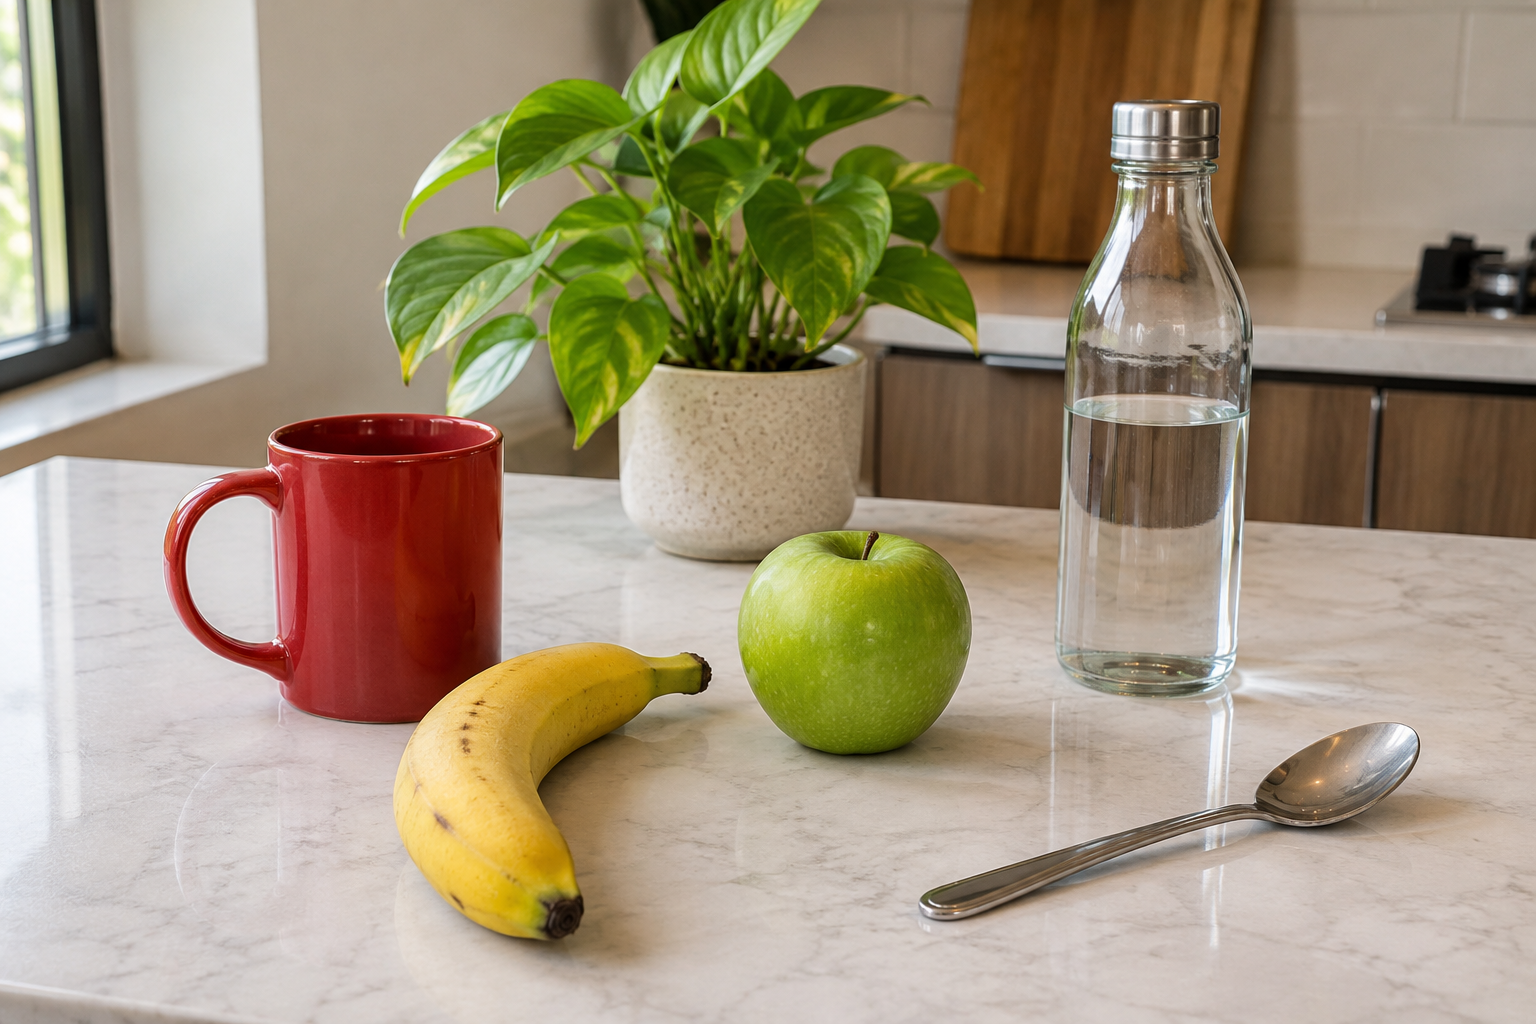

In [2]:
from google.colab import files
from PIL import Image
from IPython.display import display
from pathlib import Path

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload one image.")

image_path = next(iter(uploaded.keys()))
image = Image.open(image_path).convert("RGB")
print("Image:", image_path, "| Size:", image.size)
display(image)


### 4. Run object detection with YOLO

The pretrained YOLO model detects objects from its supported label set. The confidence threshold controls which detections are retained; it does not guarantee correctness.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


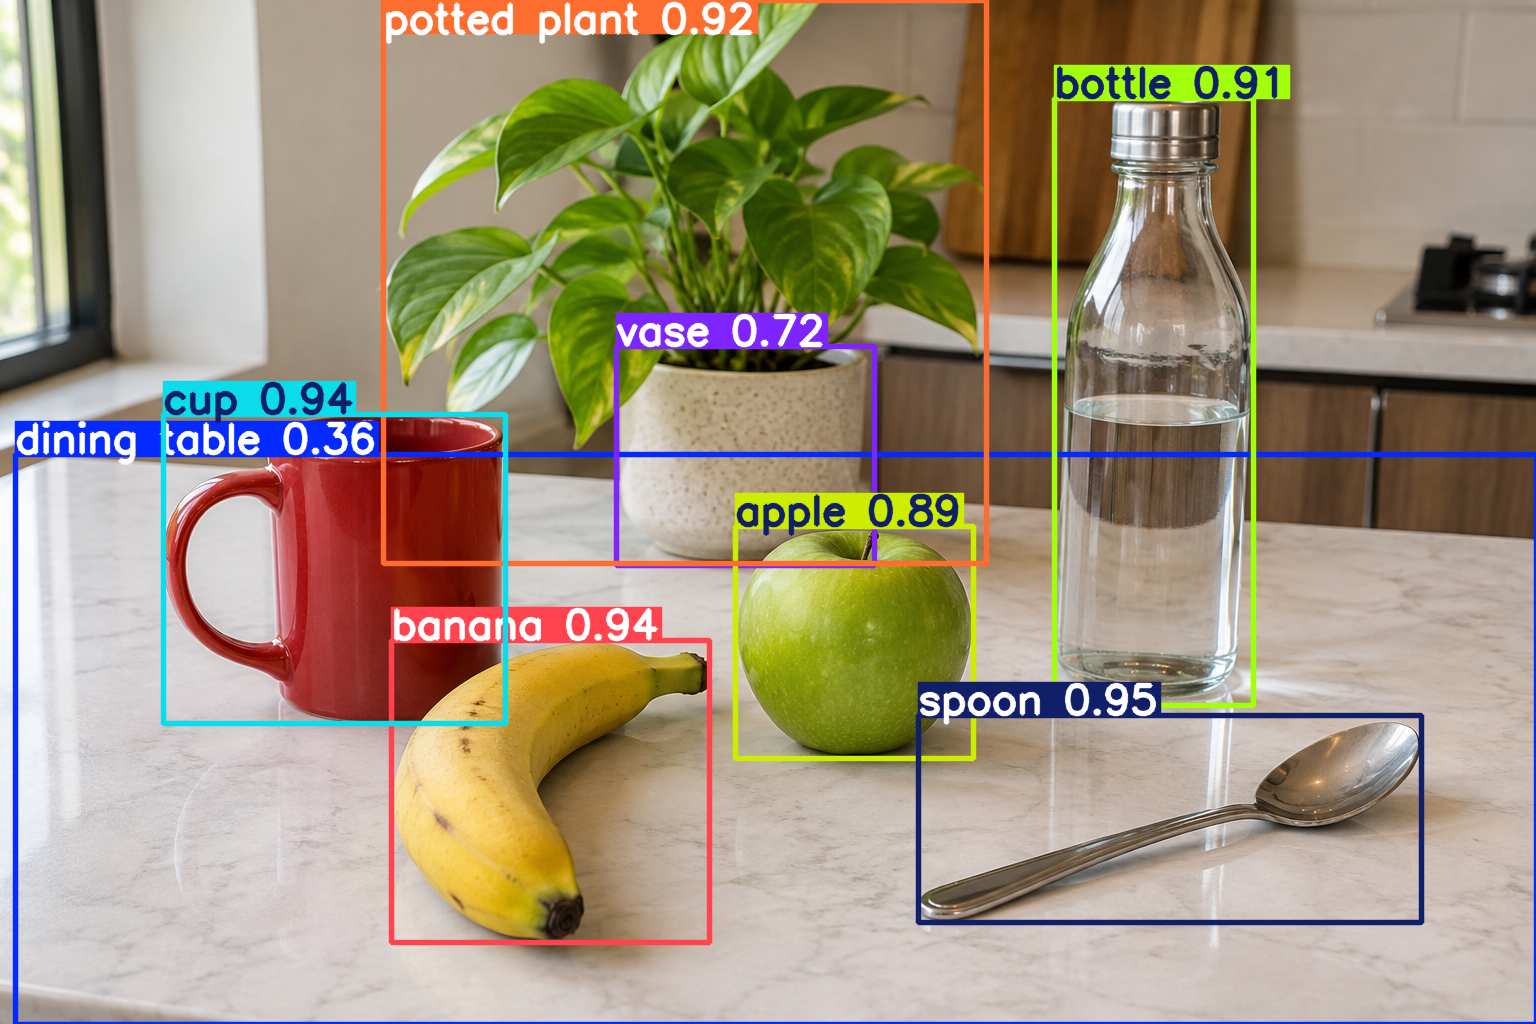

Detections:


In [3]:
from ultralytics import YOLO

detector = YOLO("yolo11n.pt")
detection_result = detector.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)[0]

annotated = detection_result.plot()
display(Image.fromarray(annotated[..., ::-1]))

print("Detections:")


In [4]:
detections = []
names = detection_result.names

if detection_result.boxes is not None:
    for box in detection_result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        xyxy = [round(float(v), 1) for v in box.xyxy[0].tolist()]
        detections.append({
            "label": names[class_id],
            "confidence": round(confidence, 4),
            "box_xyxy": xyxy
        })

for item in detections:
    print(item)

print("Total detections:", len(detections))


{'label': 'spoon', 'confidence': 0.9499, 'box_xyxy': [918.1, 715.7, 1421.8, 922.8]}
{'label': 'cup', 'confidence': 0.939, 'box_xyxy': [163.8, 414.3, 505.1, 723.9]}
{'label': 'banana', 'confidence': 0.935, 'box_xyxy': [391.7, 640.2, 709.8, 943.0]}
{'label': 'potted plant', 'confidence': 0.9213, 'box_xyxy': [383.7, 0.8, 986.4, 563.6]}
{'label': 'bottle', 'confidence': 0.9067, 'box_xyxy': [1054.8, 98.2, 1253.2, 705.1]}
{'label': 'apple', 'confidence': 0.8897, 'box_xyxy': [735.7, 526.0, 973.7, 758.4]}
{'label': 'vase', 'confidence': 0.7245, 'box_xyxy': [616.2, 346.5, 874.6, 565.1]}
{'label': 'dining table', 'confidence': 0.356, 'box_xyxy': [15.9, 454.1, 1536.0, 1024.0]}
Total detections: 8


### 5. Prepare a compact detector summary

We will pass the model's detected labels and confidence scores to the VLM. Bounding boxes are included as coordinates, but the VLM should not be asked to invent detections that are absent from this list.

In [5]:
import json

detector_summary = {
    "image_filename": Path(image_path).name,
    "detection_count": len(detections),
    "detections": detections
}

print(json.dumps(detector_summary, indent=2))


{
  "image_filename": "Bright Kitchen Countertop Still Life.png",
  "detection_count": 8,
  "detections": [
    {
      "label": "spoon",
      "confidence": 0.9499,
      "box_xyxy": [
        918.1,
        715.7,
        1421.8,
        922.8
      ]
    },
    {
      "label": "cup",
      "confidence": 0.939,
      "box_xyxy": [
        163.8,
        414.3,
        505.1,
        723.9
      ]
    },
    {
      "label": "banana",
      "confidence": 0.935,
      "box_xyxy": [
        391.7,
        640.2,
        709.8,
        943.0
      ]
    },
    {
      "label": "potted plant",
      "confidence": 0.9213,
      "box_xyxy": [
        383.7,
        0.8,
        986.4,
        563.6
      ]
    },
    {
      "label": "bottle",
      "confidence": 0.9067,
      "box_xyxy": [
        1054.8,
        98.2,
        1253.2,
        705.1
      ]
    },
    {
      "label": "apple",
      "confidence": 0.8897,
      "box_xyxy": [
        735.7,
        526.0,
        973.7,
    

### 6. Load Qwen3-VL

This downloads the model from Hugging Face.

In [6]:
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration
from qwen_vl_utils import process_vision_info

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
vlm = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

print("Loaded:", MODEL_ID)


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct


### 7. Define a helper to ask Qwen3-VL

The helper accepts an image and text instruction. It returns the generated text. I will first request an ordinary explanation, then request structured JSON.

In [7]:
def ask_vlm(image_path, prompt, max_new_tokens=350):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image_path},
            {"type": "text", "text": prompt},
        ],
    }]

    formatted_prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[formatted_prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(vlm.device)

    with torch.inference_mode():
        generated = vlm.generate(**inputs, max_new_tokens=max_new_tokens)

    generated_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(inputs.input_ids, generated)
    ]

    return processor.batch_decode(
        generated_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

print("VLM helper ready.")


VLM helper ready.


### 8. Generate a natural-language explanation

The prompt provides the detector output and asks the VLM to explain it without treating detector predictions as guaranteed truth.

In [9]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
CUDA available: True


In [10]:
explanation_prompt = f'''
You are explaining a computer-vision detection result to a user.

Here is the detector output in JSON:
{json.dumps(detector_summary, ensure_ascii=False)}

Look at the image and write a short explanation:
- Mention the main visible scene.
- Summarize the detected objects and their confidence scores.
- Clearly distinguish what is visible in the image from what the detector predicted.
- Do not invent objects or claim that a detection is certainly correct.
- If the image and detector output disagree, mention the uncertainty.
'''

natural_language_explanation = ask_vlm(
    image_path, explanation_prompt, max_new_tokens=300
)
print(natural_language_explanation)


The image shows a bright, modern kitchen countertop with a still life arrangement. Visible items include a red mug, a yellow banana, a green apple, a clear glass bottle with water, a silver spoon, and a potted plant with large green leaves in a speckled ceramic pot. In the background, a window, wooden cabinet, and a stove are visible.

The detector identified 8 objects with varying confidence scores:
- A spoon (confidence 0.95) — correctly detected as the silver spoon on the right.
- A cup (confidence 0.94) — correctly identified as the red mug.
- A banana (confidence 0.94) — correctly detected.
- A potted plant (confidence 0.92) — correctly identified.
- A bottle (confidence 0.91) — correctly detected as the glass water bottle.
- An apple (confidence 0.89) — correctly identified.
- A vase (confidence 0.72) — this is an incorrect prediction; the plant is in a pot, not a vase, and the detector’s bounding box does not match the pot.
- A dining table (confidence 0.36) — this is also incor

### 9. Define the target JSON schema

I want a predictable response with:
- `scene_summary`: short string.
- `detections`: list of objects, each with `label`, `confidence`, and `visual_evidence`.
- `limitations`: list of strings.

This is a deliberately small schema for the exercise.

In [11]:
from pydantic import BaseModel, Field, ValidationError
from typing import List

class DetectionExplanation(BaseModel):
    label: str
    confidence: float = Field(ge=0.0, le=1.0)
    visual_evidence: str

class CVExplanation(BaseModel):
    scene_summary: str
    detections: List[DetectionExplanation]
    limitations: List[str]

print(CVExplanation.model_json_schema())


{'$defs': {'DetectionExplanation': {'properties': {'label': {'title': 'Label', 'type': 'string'}, 'confidence': {'maximum': 1.0, 'minimum': 0.0, 'title': 'Confidence', 'type': 'number'}, 'visual_evidence': {'title': 'Visual Evidence', 'type': 'string'}}, 'required': ['label', 'confidence', 'visual_evidence'], 'title': 'DetectionExplanation', 'type': 'object'}}, 'properties': {'scene_summary': {'title': 'Scene Summary', 'type': 'string'}, 'detections': {'items': {'$ref': '#/$defs/DetectionExplanation'}, 'title': 'Detections', 'type': 'array'}, 'limitations': {'items': {'type': 'string'}, 'title': 'Limitations', 'type': 'array'}}, 'required': ['scene_summary', 'detections', 'limitations'], 'title': 'CVExplanation', 'type': 'object'}


### 10. Ask for schema-shaped JSON

I explicitly ask for JSON only and include the allowed detector results. The model may still return malformed JSON or values that do not match the schema; the next cells check that.

In [12]:
json_prompt = f'''
Analyze the image and the supplied object detector output.

Detector output:
{json.dumps(detector_summary, ensure_ascii=False)}

Return ONLY one valid JSON object. Do not use Markdown fences or add commentary.
Use exactly this structure:
{{
  "scene_summary": "one or two sentence summary",
  "detections": [
    {{
      "label": "label from the detector output",
      "confidence": 0.0,
      "visual_evidence": "brief evidence visible in the image"
    }}
  ],
  "limitations": ["uncertainty or limitation"]
}}

Rules:
- Use only labels that appear in the supplied detector output.
- Copy each confidence value from the detector output.
- Do not invent detections.
- If there are no detections, return an empty detections list.
- Do not infer identities or sensitive attributes.
'''

raw_json_response = ask_vlm(image_path, json_prompt, max_new_tokens=450)
print(raw_json_response)


{
  "scene_summary": "A still life arrangement on a kitchen countertop featuring a red mug, a banana, a green apple, a glass water bottle, a spoon, and a potted plant.",
  "detections": [
    {
      "label": "spoon",
      "confidence": 0.9499,
      "visual_evidence": "A metallic spoon lying on the countertop to the right of the apple."
    },
    {
      "label": "cup",
      "confidence": 0.939,
      "visual_evidence": "A red ceramic mug positioned on the left side of the countertop."
    },
    {
      "label": "banana",
      "confidence": 0.935,
      "visual_evidence": "A yellow banana lying on the countertop between the red mug and the green apple."
    },
    {
      "label": "potted plant",
      "confidence": 0.9213,
      "visual_evidence": "A green leafy plant in a speckled pot located behind the fruit and cup."
    },
    {
      "label": "bottle",
      "confidence": 0.9067,
      "visual_evidence": "A clear glass bottle with a metal cap and water inside, standing on t

### 11. Parse and validate the JSON

The parser first attempts to decode the model's complete response. If the model adds text around the JSON, we try to isolate the outermost JSON object. A successful parse is then checked against the Pydantic schema.

In [13]:
def extract_json_object(text):
    text = text.strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        start = text.find("{")
        end = text.rfind("}")
        if start == -1 or end == -1 or end <= start:
            raise ValueError("No JSON object found in model response.")
        return json.loads(text[start:end + 1])

parsed_output = None
validation_passed = False
validation_error = None

try:
    candidate = extract_json_object(raw_json_response)
    parsed_output = CVExplanation.model_validate(candidate)
    validation_passed = True
    print("Schema validation: PASSED")
    print(parsed_output.model_dump_json(indent=2))
except (ValueError, json.JSONDecodeError, ValidationError) as exc:
    validation_error = str(exc)
    print("Schema validation: FAILED")
    print(validation_error)


Schema validation: FAILED
Expecting ',' delimiter: line 43 column 6 (char 1622)


### 12. Measure schema compliance

For this notebook, schema compliance means the model response could be parsed and passed Pydantic validation. It does **not** measure whether the explanation is factually correct.

In [14]:
schema_metrics = {
    "model": MODEL_ID,
    "schema_valid": validation_passed,
    "raw_response_characters": len(raw_json_response),
    "detector_count": len(detections),
    "validation_error": validation_error
}

print(json.dumps(schema_metrics, indent=2))


{
  "model": "Qwen/Qwen3-VL-4B-Instruct",
  "schema_valid": false,
  "raw_response_characters": 1664,
  "detector_count": 8,
  "validation_error": "Expecting ',' delimiter: line 43 column 6 (char 1622)"
}


### 13. Test the validator with a deliberately invalid example

This checks that the schema rejects an invalid confidence value. It tests our validator, not the VLM.

In [15]:
invalid_example = {
    "scene_summary": "Example scene",
    "detections": [{
        "label": "car",
        "confidence": 1.7,
        "visual_evidence": "Example evidence"
    }],
    "limitations": []
}

try:
    CVExplanation.model_validate(invalid_example)
    print("Unexpected: invalid example passed.")
except ValidationError as exc:
    print("Expected validation failure:")
    print(exc)


Expected validation failure:
1 validation error for CVExplanation
detections.0.confidence
  Input should be less than or equal to 1 [type=less_than_equal, input_value=1.7, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/less_than_equal


### 14. Compare the JSON detections with the original detector output

Even schema-valid output may omit detections or misstate confidence. This check compares the labels and confidence values in the validated VLM JSON against the detector output.

In [16]:
if validation_passed:
    detector_pairs = {
        (d["label"], round(d["confidence"], 4))
        for d in detections
    }
    vlm_pairs = {
        (d.label, round(d.confidence, 4))
        for d in parsed_output.detections
    }

    print("Detector label/confidence pairs:", detector_pairs)
    print("VLM label/confidence pairs:", vlm_pairs)
    print("Pairs copied exactly:", vlm_pairs.issubset(detector_pairs))
else:
    print("Skipped comparison because VLM output did not pass schema validation.")


Skipped comparison because VLM output did not pass schema validation.


### 15. Save the experiment

Save the detector output, natural-language explanation, raw JSON response, schema-validation status, and parsed JSON (if valid).

In [17]:
from datetime import datetime

record = {
    "module": 5,
    "day": 3,
    "image_filename": Path(image_path).name,
    "detector": "Ultralytics YOLO11n",
    "vlm_model": MODEL_ID,
    "detector_output": detector_summary,
    "natural_language_explanation": natural_language_explanation,
    "raw_json_response": raw_json_response,
    "schema_metrics": schema_metrics,
    "validated_json": parsed_output.model_dump() if validation_passed else None,
    "created_at": datetime.now().isoformat(timespec="seconds")
}

output_path = Path("day3_cv_explanations.json")
output_path.write_text(
    json.dumps(record, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8"
)
print("Saved:", output_path.resolve())


Saved: /content/day3_cv_explanations.json
